# #17 Common Denominator

* Your task is to calculate the click-through rate for each channel and for the account as a whole.
* How many channels have a click-through rate of at least 4%? 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("campaign_performance.csv")

In [3]:
df

,campaign_name,channel,impressions,ctr
0,Email Non-Openers Match,Retargeting,"363,226",1.26%
1,Online Video - Trail Series,Video,"3,330,589",0.65%
2,Native - Sponsored Guides,Display,"8,255,890",0.20%
3,Creative Test - Trail Crew POV,Paid Social,"42,365",5.86%
4,Dynamic Remarketing - Category,Retargeting,"677,161",1.41%
5,Contextual - Gear Reviews,Display,"10,529,312",0.16%
6,Engaged Audiences - 180d,Paid Social,"731,739",1.25%
7,Prospecting - Broad Interest,Paid Social,"20,900,712",0.43%
8,YouTube - In-Stream Skippable,Video,"11,563,765",0.20%
9,Programmatic - Open Exchange,Display,"27,103,140",0.07%


In [4]:
df["ctr"] = df["ctr"].str.replace("%", "").astype(float)/100 #values are xx.x%
df["impressions"] = df["impressions"].str.replace(",", "").astype(int) #number with 1k separator 
df["clicks"] = df["impressions"] * df["ctr"]

In [ ]:
channel_ctr = (
    df.groupby("channel")
      .agg(
          impressions=("impressions", "sum"),
          clicks=("clicks", "sum")
      )
      .assign(
          ctr=lambda x: x["clicks"] / x["impressions"] * 100, # formula from Maven site
          clicks=lambda x: x["clicks"].astype(int)
      )
)

(channel_ctr["ctr"] >= 4).sum(), channel_ctr[channel_ctr["ctr"] >= 4].index.to_list()

(np.int64(1), ['Paid Search'])

In [7]:
channel_ctr.sort_values(by="ctr", ascending=False)

,impressions,clicks,ctr
channel,,,
Paid Search,13291625,588646,4.428702
Retargeting,5399745,69275,1.282948
Paid Social,37768487,196693,0.520786
Video,44060212,150686,0.342001
Display,102891287,116676,0.113398


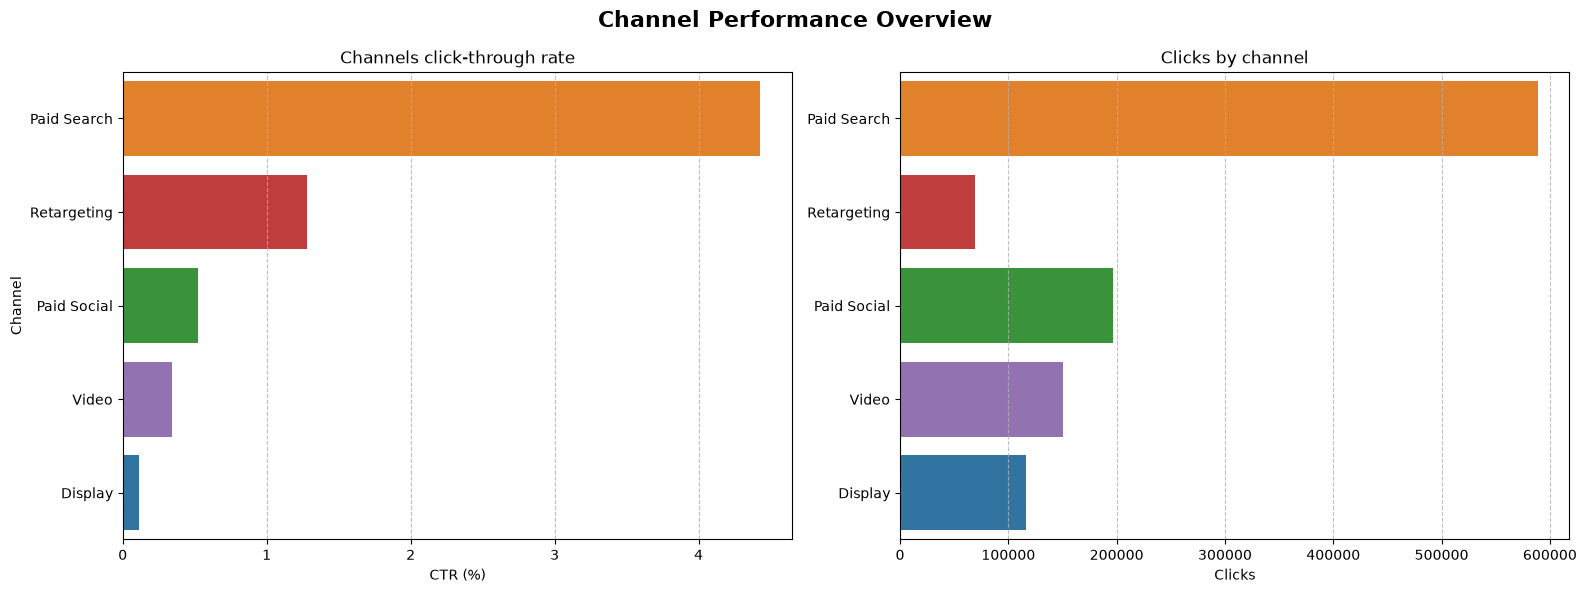

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

order = (
    channel_ctr
    .sort_values("ctr", ascending=False)
    .index
)

sns.barplot(
    data=channel_ctr,
    x="ctr",
    y="channel",
    hue="channel",
    order=order,
    ax=ax[0]
)

sns.barplot(
    data=channel_ctr,
    x="clicks",
    y="channel",
    hue="channel",
    order=order,
    ax=ax[1]
)

ax[0].grid(axis="x", linestyle="--", alpha=0.8)
ax[1].grid(axis="x", linestyle="--", alpha=0.8)

fig.suptitle("Channel Performance Overview", fontsize=16, fontweight="bold")

ax[0].set_title("Channels click-through rate")
ax[0].set_xlabel("CTR (%)")
ax[0].set_ylabel("Channel")

ax[1].set_title("Clicks by channel")
ax[1].set_xlabel("Clicks")
ax[1].set_ylabel("")


plt.tight_layout()
plt.show()

In [11]:
top10 = (
    df[df["impressions"] >= 10_000] # only campaigns with at least 10K impressions
    .sort_values("ctr", ascending=False)
    .head(10)
)

In [12]:
top10

,campaign_name,channel,impressions,ctr,clicks
44,Creative Test - Founder Story,Paid Social,27078,0.0882,2388.2796
32,Creative Test - UGC Summit Reel,Paid Social,14892,0.0880,1310.4960
18,Creative Test - Gear Teardown,Paid Social,34875,0.0740,2580.7500
28,Creative Test - Winter Carousel,Paid Social,46324,0.0707,3275.1068
3,Creative Test - Trail Crew POV,Paid Social,42365,0.0586,2482.5890
11,Creative Test - Pack Fit Guide,Paid Social,70125,0.0548,3842.8500
21,Creative Test - Repair Promise,Paid Social,86598,0.0546,4728.2508
42,Brand Terms - Exact,Paid Search,2986381,0.0532,158875.4692
24,Brand Terms - Phrase,Paid Search,1586452,0.0487,77260.2124
45,Shopping - Clearance,Paid Search,389927,0.0468,18248.5836


In [13]:
pareto = (
    df.sort_values("clicks")
      .assign(
          cum_clicks=lambda x: x["clicks"].cumsum(),
          cum_prc=lambda x: x["cum_clicks"] / x["clicks"].sum()
      )
)

In [14]:
pareto[pareto["cum_prc"] >= 0.8]

,campaign_name,channel,impressions,ctr,clicks,cum_clicks,cum_prc
25,Shopping - Core Catalog,Paid Search,2170221,0.0449,97442.9229,9.631026e+05,0.858397
42,Brand Terms - Exact,Paid Search,2986381,0.0532,158875.4692,1.121978e+06,1.000000


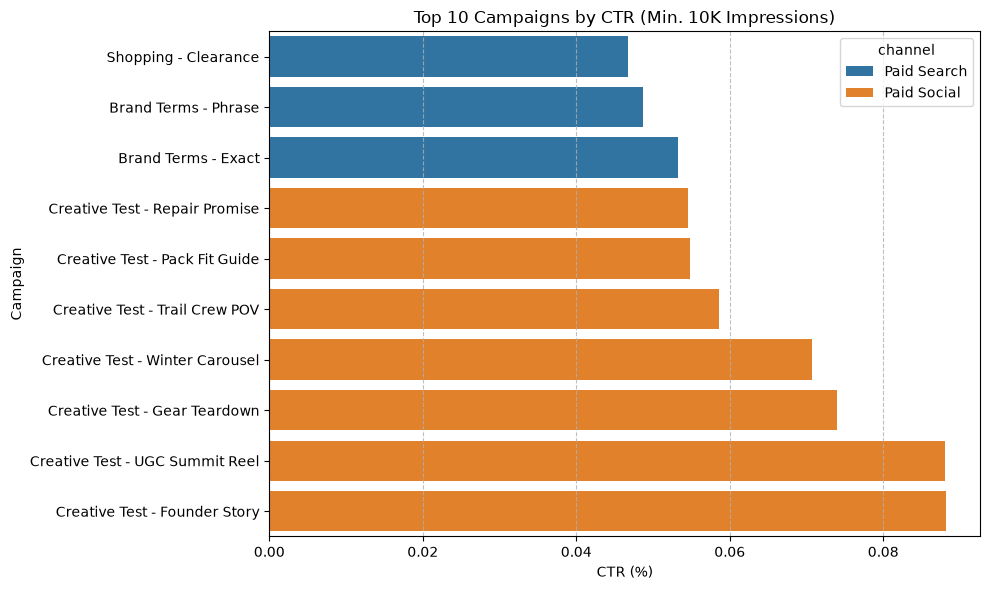

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=top10.sort_values("ctr"),
    x="ctr",
    y="campaign_name",
    hue="channel",
    ax=ax
)

ax.grid(axis="x", linestyle="--", alpha=0.8)

ax.set_title("Top 10 Campaigns by CTR (Min. 10K Impressions)")
ax.set_xlabel("CTR (%)")
ax.set_ylabel("Campaign")


plt.tight_layout()
plt.show()